In [ ]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensembxle as IETLMC
from Python_files import GETLM as GETLMC
from Python_files import GETLM_experiment_neat as GEN
#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
# we now define stuff as required
model = TST.rk4_L96

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.05 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)

perturbation_size = 10**(-7)
ensemble_size = 24
num_steps = 10
trials = 30
LETLM_stencil = [[0], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5]]
IETLM_stencil = [[-2,-1,0,1], [-2,-1,0,1]]
GETLM_stencil = [[2,-1,0,1],[-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5],[2,-1,0,1]]

x_values = np.arange(1, num_steps+1)  


In [10]:

LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = GEN.GETLM_experiment_trials(model, model_parameters, perturbation_size, ensemble_size, num_steps, trials, LETLM_stencil, IETLM_stencil, GETLM_stencil)
# print(LETLM_TT_result.shape)

100%|██████████| 30/30 [00:12<00:00,  2.42it/s]


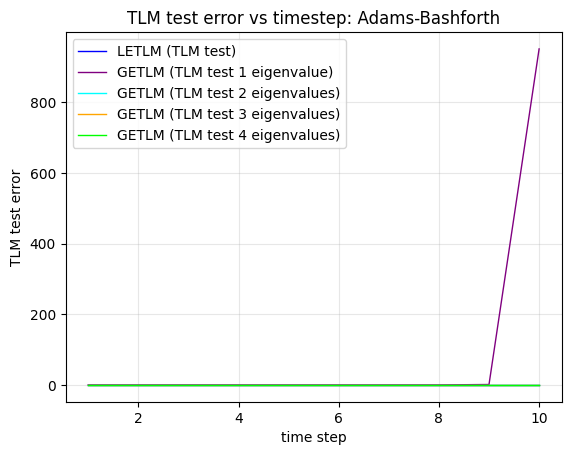

<Figure size 640x480 with 0 Axes>

In [11]:
# plt.plot(x_values, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Adams-Bashforth")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

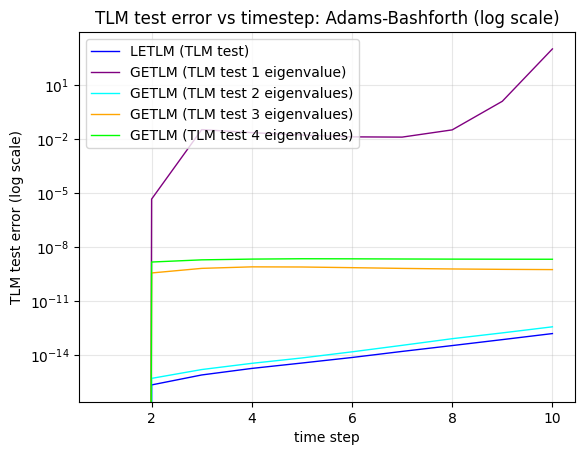

<Figure size 640x480 with 0 Axes>

In [12]:
# plt.plot(x_values, IETLM_TT_result, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values, LETLM_TT_result, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values, GETLM_1_TT_result, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values, GETLM_2_TT_result, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values, GETLM_3_TT_result, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values, GETLM_4_TT_result, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Adams-Bashforth (log scale)")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

In [13]:
RK4_LETLM = LETLM_TT_result
RK4_IELTM = IETLM_TT_result
RK4_GETLM = GETLM_2_TT_result

In [14]:
plt.plot(x_values, AB_LETLM, label='Adams-Bashforth (LETLM)', color='red', linewidth=1, linestyle = '-' )
plt.plot(x_values, AB_IELTM, label='Adams-Bashforth (IETLM)', color='blue', linewidth=1, linestyle = '-')
plt.plot(x_values, AB_GETLM, label='Adams-Bashforth (GETLM)', color='green', linewidth=1, linestyle = '-')

plt.plot(x_values, CN_LETLM, label='Crank-Nicolson (LETLM)', color='red', linewidth=1, linestyle = '--' )
plt.plot(x_values, CN_IELTM, label='Crank-Nicolson (IETLM)', color='blue', linewidth=1, linestyle = '--')
plt.plot(x_values, CN_GETLM, label='Crank-Nicolson (GETLM)', color='green', linewidth=1, linestyle = '--')

plt.plot(x_values, RK4_LETLM, label='Crank-Nicolson (LETLM)', color='red', linewidth=1, linestyle = '-.' )
plt.plot(x_values, RK4_IELTM, label='Crank-Nicolson (IETLM)', color='blue', linewidth=1, linestyle = '-.')
plt.plot(x_values, RK4_GETLM, label='Crank-Nicolson (GETLM)', color='green', linewidth=1, linestyle = '-.')



plt.title("TLM test error vs timestep")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    ncols=2,             # Arranges items horizontally instead of vertically
    frameon=True         # Optional: adds a border box around the legend
)
plt.grid(True, alpha=0.3)
# plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

NameError: name 'AB_LETLM' is not defined

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(x_values, AB_LETLM, label='Adams-Bashforth (LETLM)', color='red', linewidth=1, linestyle = '-' )
plt.plot(x_values, AB_IELTM, label='Adams-Bashforth (IETLM)', color='blue', linewidth=1, linestyle = '-')
plt.plot(x_values, AB_GETLM, label='Adams-Bashforth (GETLM)', color='green', linewidth=1, linestyle = '-')

plt.plot(x_values, CN_LETLM, label='Crank-Nicolson (LETLM)', color='red', linewidth=1, linestyle = '--' )
plt.plot(x_values, CN_IELTM, label='Crank-Nicolson (IETLM)', color='blue', linewidth=1, linestyle = '--')
plt.plot(x_values, CN_GETLM, label='Crank-Nicolson (GETLM)', color='green', linewidth=1, linestyle = '--')

plt.plot(x_values, RK4_LETLM, label='Runge-Kutta 4 (LETLM)', color='red', linewidth=1, linestyle = '-.' )
plt.plot(x_values, RK4_IELTM, label='Runge-Kutta 4 (IETLM)', color='blue', linewidth=1, linestyle = '-.')
plt.plot(x_values, RK4_GETLM, label='Runge-Kutta 4 (GETLM)', color='green', linewidth=1, linestyle = '-.')




plt.title("TLM test error vs timestep(log scale)")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    ncols=3,             # Arranges items horizontally instead of vertically
    frameon=True         # Optional: adds a border box around the legend
)
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()